In [1]:
 #Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path


import warnings
warnings.filterwarnings('ignore')

In [2]:
data2 = pd.read_excel('oct_data.xlsx', sheet_name= 'Low-freq buyers (enriched)')

data2.head()

,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,phone_number,unpaid_policies,pwa_sales,old_platform_sales,last_sale_date
0,43,136,2,21.5,5,6,Eastman Magembe,NaN,emagembe2019@gmail.com,254705440772,0,3,2,2026-10-30
1,35,78,2,17.5,20,29,Benson Anunda Simiyu,Nairobi City,anundabenson2002@gmail.com,254112572179,3,19,1,2026-10-19
2,17,53,1,17.0,218,237,Simon Mwandima,Nairobi City,nadimainsurance@gmail.com,254722518214,2,20,198,2026-10-02
3,12,37,1,12.0,104,102,James Muoki,Nairobi City,jmuoki88@gmail.com,254714831970,5,76,28,2026-10-15
4,11,44,1,11.0,2,11,ROSE MULI,Nairobi City,rose@fursainsurance.co.ke,254111667594,0,2,0,2026-10-01


In [3]:
data2['last_sale_date'].isna().sum()

0

In [4]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1204 entries, 0 to 1203
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   products_viewed     1204 non-null   int64         
 1   view_events         1204 non-null   int64         
 2   sales_since_sep30   1204 non-null   int64         
 3   viewed_per_sale     1204 non-null   float64       
 4   all_sales_alltime   1204 non-null   int64         
 5   quotes_alltime      1204 non-null   int64         
 6   user_name           1204 non-null   object        
 7   county              1199 non-null   object        
 8   email               1204 non-null   object        
 9   phone_number        1204 non-null   int64         
 10  unpaid_policies     1204 non-null   int64         
 11  pwa_sales           1204 non-null   int64         
 12  old_platform_sales  1204 non-null   int64         
 13  last_sale_date      1204 non-null   datetime64[n

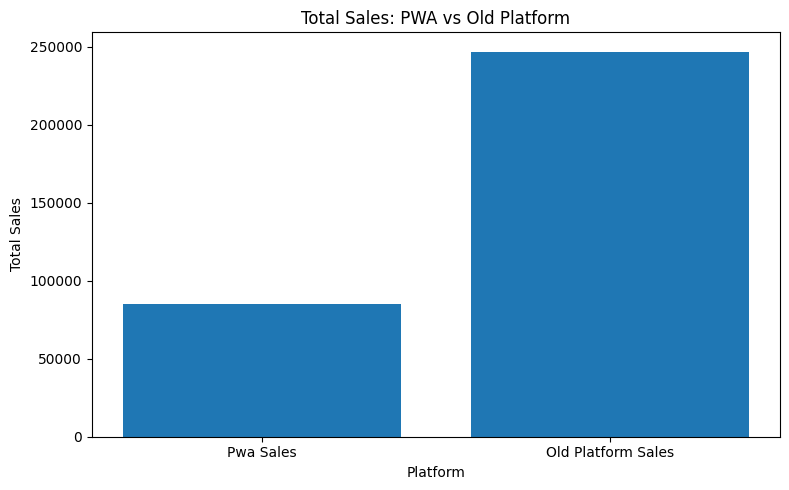

In [5]:
pwa_total = data2['pwa_sales'].sum()
old_total = data2['old_platform_sales'].sum()

platforms = ['Pwa Sales', 'Old Platform Sales']
sales = [pwa_total, old_total]

plt.figure(figsize=(8,5))
bars = plt.bar(platforms, sales)

plt.title('Total Sales: PWA vs Old Platform')
plt.ylabel('Total Sales')
plt.xlabel('Platform')
plt.tight_layout()
plt.show()

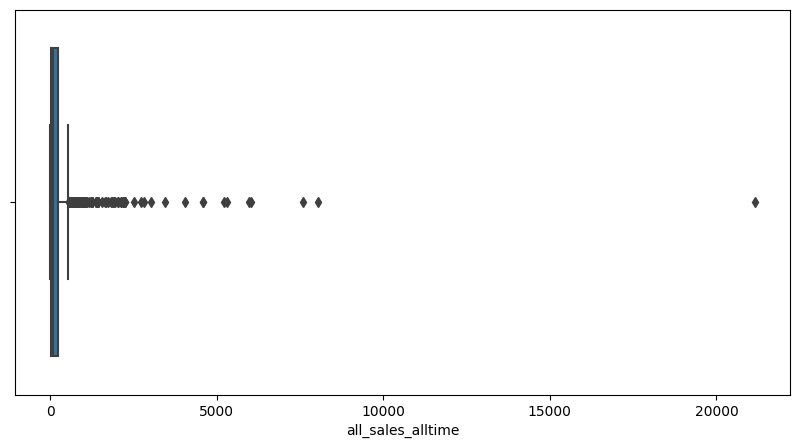

In [6]:
plt.figure(figsize=(10,5))
sns.boxplot(x=data2['all_sales_alltime']);

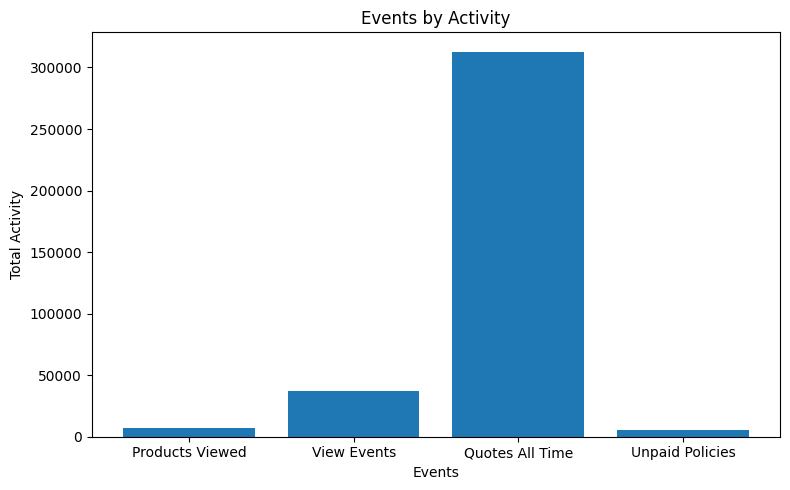

In [7]:
products_viewed_total = data2['products_viewed'].sum()
view_events_total = data2['view_events'].sum()
quotes_alltime_total = data2['quotes_alltime'].sum()
unpaid_total = data2['unpaid_policies'].sum()


events = ['Products Viewed', 'View Events', 'Quotes All Time', 'Unpaid Policies']
activity = [products_viewed_total, view_events_total, quotes_alltime_total, unpaid_total]

plt.figure(figsize=(8,5))
bars = plt.bar(events, activity)

plt.title('Events by Activity')
plt.ylabel('Total Activity')
plt.xlabel('Events')
plt.tight_layout()
plt.show()

In [8]:
latest_date = data2['last_sale_date'].max()   #the most recent date
latest_date

#days since last sale
data2['days_since_last_sale'] = (latest_date - data2['last_sale_date']).dt.days

#categorise agents
data2['sales_recency'] = pd.cut(
    data2['days_since_last_sale'],
    bins = [-1, 30, float('inf')],
    labels = ['Recent (0- 30 days)', 'Inactive (> 30 days)']
)

#missing dates
data2['sales_recency'] = data2['sales_recency'].cat.add_categories('No Sales').fillna('No Sales')

In [9]:
data2['sales_recency'].value_counts()

sales_recency
Recent (0- 30 days)     1194
Inactive (> 30 days)      10
No Sales                   0
Name: count, dtype: int64

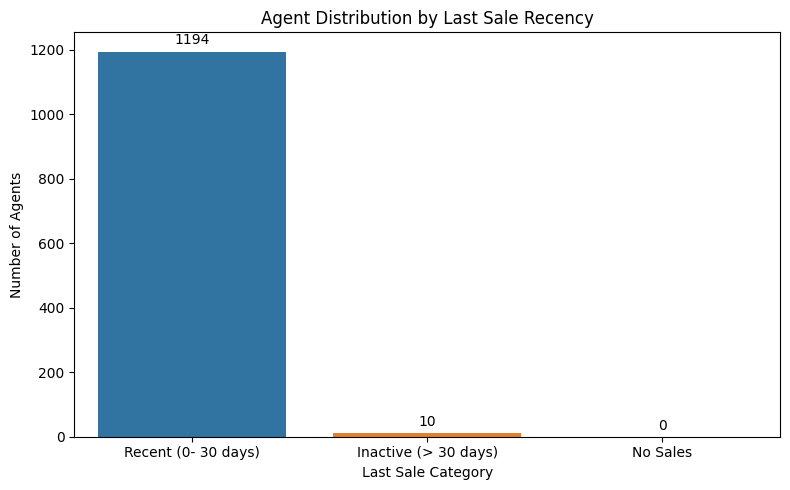

In [10]:
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=data2,
    x ='sales_recency',
    order = [
        'Recent (0- 30 days)',
        'Inactive (> 30 days)',
        'No Sales'
    ]
)

plt.title('Agent Distribution by Last Sale Recency')
plt.xlabel('Last Sale Category')
plt.ylabel('Number of Agents')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()